# Data load

In [1]:
import pandas as pd

custom=False # custom=False - for Meredig or Magpie features
magpie=True # magpie=False - for Meredig features / magpie=True - for Magpie features

if custom:
    file_name = './data/composition/X_custom.csv'
elif magpie:
    file_name = './data/X_magpie.csv'
else:
    file_name = './data/X_meredig.csv'
X=pd.read_csv(file_name)

if custom:
    file_name = './data/composition/y1_custom.csv'
elif magpie:
    file_name = './data/y1_magpie.csv'
else:
    file_name = './data/y1_meredig.csv'
y1=pd.read_csv(file_name)

if custom:  
    file_name = './data/composition/y2_custom.csv'
elif magpie:
    file_name = './data/y2_magpie.csv'
else:
    file_name = './data/y2_meredig.csv'
y2=pd.read_csv(file_name)

# Function definitions

In [2]:
import time, os, json, joblib
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import platform

if "Intel" in platform.processor():
  from sklearnex import patch_sklearn
  patch_sklearn()

from sklearnex import patch_sklearn
patch_sklearn()

model_path='./models'
dane_path='./data'

def model_plot(model, X_test, y_test, duration):
    
    y_pred=model.predict(X_test)

# Ocena modelu
    R2 = round(r2_score(y_test, y_pred), 4)
    print(f'R2: {R2}')
    mse = round(mean_squared_error(y_test, y_pred), 4)
    print(f'Mean Squared Error: {mse}')
    mae = round(mean_absolute_error(y_test, y_pred), 4)
    print(f'Mean Absolute Error: {mae}')
    print(f'Fit time: {round(duration, 3)} s')

# plot the fit
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.1)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Exp.')
    plt.ylabel('Predicted')
    plt.grid()
    plt.show()

def save_params(path, model, model_name=''):

  if model_name=='':
    model_name=str(model)

  plik=os.path.join(path, 'hyperparameters.json')

  # Sprawdź, czy plik istnieje
  if os.path.exists(plik):
    # Załaduj istniejące hiperparametry z pliku
    with open(plik, 'r') as file:
        hyperparameters = json.load(file)
  else:
    # Utwórz nowy słownik hiperparametrów
    hyperparameters = {}

  # Dodaj hiperparametry nowego modelu
  hyperparameters[model_name] = model.get_params()

  # Zapisz zaktualizowane hiperparametry do pliku
  with open(plik, 'w') as file:
    json.dump(hyperparameters, file)

  joblib.dump(model, os.path.join(path, model_name + '.joblib'))


def fit_params(model, param_grid, X_train, y_train, X_test, y_test):
  # Utwórz obiekt GridSearchCV
  grid_search = GridSearchCV(model, param_grid, cv=5, n_jobs=-1)

  # Dopasuj model do danych treningowych
  start_time = time.time()
  grid_search.fit(X_train, y_train)
  duration = time.time() - start_time

  # Wyświetlenie najlepszych parametrów
  print("Najlepsze parametry: ", grid_search.best_params_)

  # compute performance on test set
  model = grid_search.best_estimator_

  model_plot(model, X_test, y_test, duration)

  return model, grid_search.best_estimator_

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


# Density

## Train/test split

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y1, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y1, train_size=800, test_size=200, random_state=42)

#X_train.to_csv('./data/X_train.csv', index=False)
#X_test.to_csv('./data/X_test.csv', index=False) 
y_train.to_csv('./data/y_train.csv', index=False)
y_test.to_csv('./data/y_test.csv', index=False)

y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

print(X_train.shape)
print(X_test.shape)

(800, 42)
(200, 42)


## Standarization 

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import normalize

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

pd.DataFrame(X_train).to_csv('./data/X_train.csv', index=False)
pd.DataFrame(X_test).to_csv('./data/X_test.csv', index=False)


## Loading data for ML

In [5]:
import pandas as pd
import numpy as np

data_path = './data/'

X_train = pd.read_csv(os.path.join(data_path, 'X_train.csv')).values
X_test = pd.read_csv(os.path.join(data_path, 'X_test.csv')).values       
y_train = pd.read_csv(os.path.join(data_path, 'y_train.csv')).values.ravel()
y_test = pd.read_csv(os.path.join(data_path, 'y_test.csv')).values.ravel()

## Linear regression

R2: 0.8898
Mean Squared Error: 0.0921
Mean Absolute Error: 0.1938
Fit time: 0.202 s


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.147671e-01, tolerance: 6.882e-02
  model = cd_fast.enet_coordinate_descent(


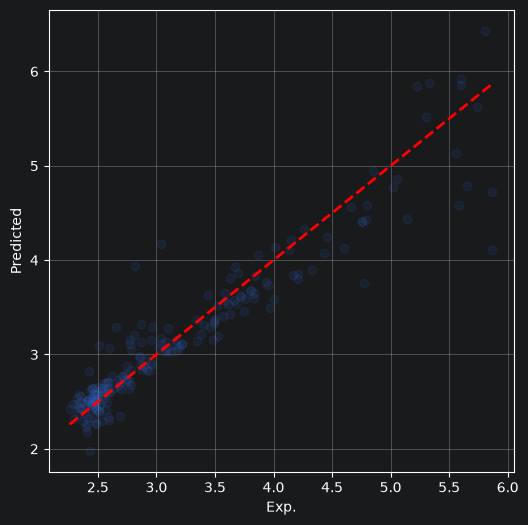

In [6]:
from sklearn.linear_model import ElasticNet

# Create a Lasso regression model
model = ElasticNet(alpha=0.0001, l1_ratio=0.5, max_iter=10000, random_state=42)

# Train the model
start_time = time.time()
model.fit(X_train, y_train)
duration = time.time() - start_time

model_plot(model, X_test, y_test, duration)

save_params(model_path, model, 'LinReg_Dens_def')

### Hyperparameters tuning

In [7]:
import numpy as np
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV


# 2. Definiowanie modelu i siatki hiperparametrów
# Chcemy przetestować różne wartości 'alpha'
model_ridge = ElasticNet()

# Definiujemy siatkę wartości alpha do sprawdzenia.
# Używamy np.logspace, aby przeszukać wartości w skali logarytmicznej.
param_grid = {
    'alpha': np.logspace(-4, 4, 50),  # 50 wartości od 0.0001 do 10000
    'l1_ratio': [0.1, 0.5, 0.9],  # Proporcja L1 do L2
    'max_iter': [10000],  # Maksymalna liczba iteracji
}


# 3. Konfiguracja i uruchomienie GridSearchCV
# Używamy scoring='neg_root_mean_squared_error', by minimalizować błąd RMSE
grid_search = GridSearchCV(
    estimator=model_ridge,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5, # 5-krotna walidacja krzyżowa
    verbose=1
)

grid_search.fit(X_train, y_train)


# 4. Wyświetlenie najlepszych wyników
print("\nNajlepsza znaleziona wartość hiperparametru 'alpha':")
print(grid_search.best_params_)

print("\nNajlepszy wynik (RMSE na zbiorze walidacyjnym):")
# Wynik jest ujemny, więc bierzemy wartość bezwzględną
best_rmse = -grid_search.best_score_
print(f"{best_rmse:.4f}")

# Najlepszy model jest dostępny w grid_search.best_estimator_
best_model = grid_search.best_estimator_

# Predykcje na zbiorze testowym
y_pred = best_model.predict(X_test)

# Obliczenie metryk na zbiorze testowym
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nWyniki Random Forest na zbiorze testowym:")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R^2 Score: {r2:.4f}")

Fitting 5 folds for each of 150 candidates, totalling 750 fits


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.447934e+00, tolerance: 5.699e-02
  model = cd_fast.enet_coordinate_descent(
C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.157270e+00, tolerance: 5.545e-02
  model = cd_fast.enet_coordinate_descent(
C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider incre


Najlepsza znaleziona wartość hiperparametru 'alpha':
{'alpha': np.float64(0.0029470517025518097), 'l1_ratio': 0.9, 'max_iter': 10000}

Najlepszy wynik (RMSE na zbiorze walidacyjnym):
0.3017

Wyniki Random Forest na zbiorze testowym:
Root Mean Squared Error (RMSE): 0.3084
Mean Absolute Error (MAE): 0.1948
R^2 Score: 0.8863


In [8]:
import joblib

# Pobieramy słownik z najlepszymi parametrami z obiektu RandomizedSearchCV
best_params = grid_search.best_params_

# Definiujemy nazwę pliku
params_filename = './models/LinReg_Dens_best_params.joblib'
model_filename = './models/LinReg_Dens_best_model.joblib'

# Zapisujemy słownik do pliku za pomocą joblib.dump()
joblib.dump(best_params, params_filename)
joblib.dump(best_model, model_filename)

print(f"Najlepsze parametry zostały pomyślnie zapisane do pliku: '{params_filename}'")
print("\nZawartość zapisanych parametrów:")
print(best_params)

# --- Jak wczytać te parametry z powrotem? ---
# Wczytujemy obiekt z pliku za pomocą joblib.load()
loaded_params = joblib.load(params_filename)

print(f"\nParametry wczytane z pliku '{params_filename}':")
print(loaded_params)

Najlepsze parametry zostały pomyślnie zapisane do pliku: './models/LinReg_Dens_best_params.joblib'

Zawartość zapisanych parametrów:
{'alpha': np.float64(0.0029470517025518097), 'l1_ratio': 0.9, 'max_iter': 10000}

Parametry wczytane z pliku './models/LinReg_Dens_best_params.joblib':
{'alpha': np.float64(0.0029470517025518097), 'l1_ratio': 0.9, 'max_iter': 10000}


## Support Vector Regression

R2: 0.904
Mean Squared Error: 0.0803
Mean Absolute Error: 0.1547
Fit time: 0.088 s


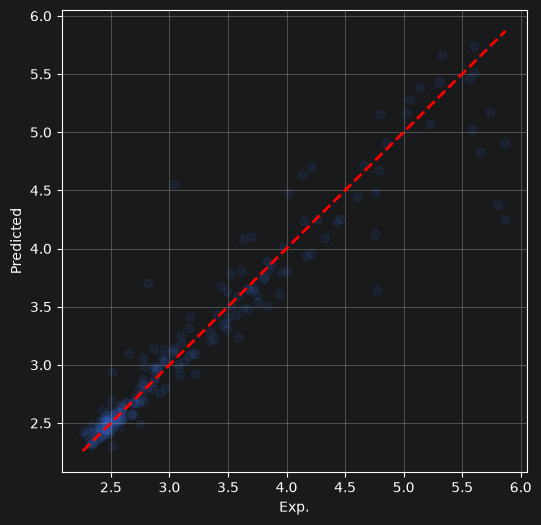

In [9]:
from sklearn.svm import SVR

# Create a Lasso regression model
model = SVR(kernel='rbf')

# Train the model
start_time = time.time()
model.fit(X_train, y_train)
duration = time.time() - start_time

model_plot(model, X_test, y_test, duration)

save_params(model_path, model, 'SVR_Dens_def')

### Hyperparameter tuning for SVR

In [10]:
import numpy as np
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV


# 2. Definiowanie modelu i siatki hiperparametrów
# Chcemy przetestować różne wartości 'C' i 'epsilon'
model_ridge = SVR(kernel='rbf')

# Definiujemy siatkę wartości C i epsilon do sprawdzenia.
# Używamy np.logspace, aby przeszukać wartości w skali logarytmicznej.
param_grid = {
    'C': np.logspace(-4, 4, 10),  # 10 wartości od 0.0001 do 10000
    'epsilon': np.linspace(0.01, 1.0, 10)  # 10 wartości od 0.01 do 1.0 
}
    


# 3. Konfiguracja i uruchomienie GridSearchCV
# Używamy scoring='neg_root_mean_squared_error', by minimalizować błąd RMSE
grid_search = GridSearchCV(
    estimator=model_ridge,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3, # 5-krotna walidacja krzyżowa
    verbose=1
)

grid_search.fit(X_train, y_train)


# 4. Wyświetlenie najlepszych wyników
print("\nNajlepsza znaleziona wartość hiperparametru 'alpha':")
print(grid_search.best_params_)

print("\nNajlepszy wynik (RMSE na zbiorze walidacyjnym):")
# Wynik jest ujemny, więc bierzemy wartość bezwzględną
best_rmse = -grid_search.best_score_
print(f"{best_rmse:.4f}")

# Najlepszy model jest dostępny w grid_search.best_estimator_
best_model = grid_search.best_estimator_

# Predykcje na zbiorze testowym
y_pred = best_model.predict(X_test)

# Obliczenie metryk na zbiorze testowym
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nWyniki Random Forest na zbiorze testowym:")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R^2 Score: {r2:.4f}")

Fitting 3 folds for each of 100 candidates, totalling 300 fits

Najlepsza znaleziona wartość hiperparametru 'alpha':
{'C': np.float64(2.782559402207126), 'epsilon': np.float64(0.01)}

Najlepszy wynik (RMSE na zbiorze walidacyjnym):
0.2935

Wyniki Random Forest na zbiorze testowym:
Root Mean Squared Error (RMSE): 0.2845
Mean Absolute Error (MAE): 0.1392
R^2 Score: 0.9032


In [11]:
import joblib

# Pobieramy słownik z najlepszymi parametrami z obiektu RandomizedSearchCV
best_params = grid_search.best_params_

# Definiujemy nazwę pliku
params_filename = './models/SVR_Dens_best_params.joblib'
model_filename = './models/SVR_Dens_best_model.joblib'

# Zapisujemy słownik do pliku za pomocą joblib.dump()
joblib.dump(best_params, params_filename)
joblib.dump(best_model, model_filename)

print(f"Najlepsze parametry zostały pomyślnie zapisane do pliku: '{params_filename}'")
print("\nZawartość zapisanych parametrów:")
print(best_params)

# --- Jak wczytać te parametry z powrotem? ---
# Wczytujemy obiekt z pliku za pomocą joblib.load()
loaded_params = joblib.load(params_filename)

print(f"\nParametry wczytane z pliku '{params_filename}':")
print(loaded_params)

Najlepsze parametry zostały pomyślnie zapisane do pliku: './models/SVR_Dens_best_params.joblib'

Zawartość zapisanych parametrów:
{'C': np.float64(2.782559402207126), 'epsilon': np.float64(0.01)}

Parametry wczytane z pliku './models/SVR_Dens_best_params.joblib':
{'C': np.float64(2.782559402207126), 'epsilon': np.float64(0.01)}


## Random Forest

R2: 0.9265
Mean Squared Error: 0.0615
Mean Absolute Error: 0.1402
Fit time: 0.313 s


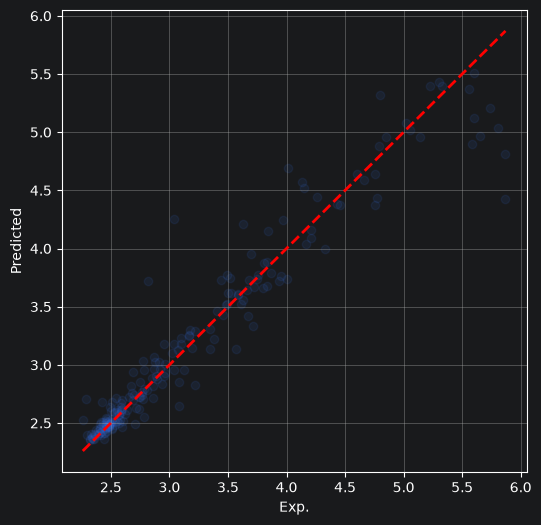

Ready!


In [12]:
from sklearn.ensemble import RandomForestRegressor

params = {'bootstrap': True, 
          'max_depth': 60, 
          'min_samples_leaf': 1, 
          'min_samples_split': 2, 
          'n_estimators': 500
         }

# Create a logistic regression model
model = RandomForestRegressor(random_state=42, **params, n_jobs=-1) #n_jobs=12

# Train the model
start_time = time.time()
model.fit(X_train, y_train)
duration = time.time() - start_time

model_plot(model, X_test, y_test, duration)

save_params(model_path, model, 'RandomForest_Dens_def')

print('Ready!')

In [13]:
importances = model.feature_importances_

importances_df = pd.DataFrame({'feature': X.columns, 'importance': importances})
importances_df = importances_df.sort_values(by='importance', ascending=False)       

importances_df

,feature,importance
10,MagpieData mean AtomicWeight,8.493262e-01
40,MagpieData mean GSvolume_pa,2.787782e-02
28,MagpieData avg_dev NpValence,1.317015e-02
35,MagpieData mean NValence,9.563708e-03
36,MagpieData avg_dev NValence,7.334078e-03
27,MagpieData mean NpValence,7.077545e-03
0,formers_frac,6.908463e-03
30,MagpieData mean NdValence,6.149581e-03
20,MagpieData avg_dev Electronegativity,6.089420e-03
9,MagpieData maximum AtomicWeight,5.290009e-03


### Hyperparameters tuning

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

rf_params = {
    'n_estimators': [100, 200, 300, 500, 1000],
    'max_depth': [None, 10, 20, 30, 40, 50],  # None oznacza brak limitu
    'max_features': ['sqrt', 'log2', 1.0], # 1.0 oznacza to samo co None w starszych wersjach - wszystkie cechy
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False] # Zazwyczaj True jest lepsze
}

# Inicjalizacja regresora Lasu Losowego
rf_regressor = RandomForestRegressor(random_state=42, n_jobs=-1)

# Definicja strategii walidacji krzyżowej (ta sama co poprzednio)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Konfiguracja RandomizedSearchCV dla Lasu Losowego
# Zauważ, jak mało się zmienia w stosunku do XGBoost!
random_search_rf = RandomizedSearchCV(
    estimator=rf_regressor,
    param_distributions=rf_params,
    n_iter=50,  # Liczba losowych kombinacji do przetestowania
    scoring='neg_root_mean_squared_error', # Ta sama metryka co dla XGBoost
    n_jobs=-1,
    cv=kfold,
    verbose=1,
    random_state=42
)

# Uruchomienie wyszukiwania
random_search_rf.fit(X_train, y_train)

# Wyświetlenie najlepszych znalezionych hiperparametrów
print("Najlepsze znalezione hiperparametry dla Random Forest:")
print(random_search_rf.best_params_)

# Wyświetlenie najlepszego wyniku walidacji krzyżowej
best_rmse_rf = -random_search_rf.best_score_
print(f"\nNajlepszy wynik RMSE (walidacja krzyżowa): {best_rmse_rf:.4f}")

# Przypisanie najlepszego modelu do zmiennej
best_model = random_search_rf.best_estimator_

# Predykcje na zbiorze testowym
y_pred_rf = best_model.predict(X_test)

# Obliczenie metryk na zbiorze testowym
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"\nWyniki Random Forest na zbiorze testowym:")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.4f}")
print(f"Mean Absolute Error (MAE): {mae_rf:.4f}")
print(f"R^2 Score: {r2_rf:.4f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Najlepsze znalezione hiperparametry dla Random Forest:
{'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 10, 'bootstrap': True}

Najlepszy wynik RMSE (walidacja krzyżowa): 0.2728

Wyniki Random Forest na zbiorze testowym:
Root Mean Squared Error (RMSE): 0.2455
Mean Absolute Error (MAE): 0.1404
R^2 Score: 0.9279


In [15]:
import joblib

# Pobieramy słownik z najlepszymi parametrami z obiektu RandomizedSearchCV
best_params = random_search_rf.best_params_

# Definiujemy nazwę pliku
params_filename = './models/RandomForest_Dens_best_params.joblib'
model_filename = './models/RandomForest_Dens_best_model.joblib'

# Zapisujemy słownik do pliku za pomocą joblib.dump()
joblib.dump(best_params, params_filename)
joblib.dump(best_model, model_filename)

print(f"Najlepsze parametry zostały pomyślnie zapisane do pliku: '{params_filename}'")
print("\nZawartość zapisanych parametrów:")
print(best_params)

# --- Jak wczytać te parametry z powrotem? ---
# Wczytujemy obiekt z pliku za pomocą joblib.load()
loaded_params = joblib.load(params_filename)

print(f"\nParametry wczytane z pliku '{params_filename}':")
print(loaded_params)

Najlepsze parametry zostały pomyślnie zapisane do pliku: './models/RandomForest_Dens_best_params.joblib'

Zawartość zapisanych parametrów:
{'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 10, 'bootstrap': True}

Parametry wczytane z pliku './models/RandomForest_Dens_best_params.joblib':
{'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 10, 'bootstrap': True}


## XGBoost

R2: 0.9056
Mean Squared Error: 0.079
Mean Absolute Error: 0.1647
Fit time: 1.14 s


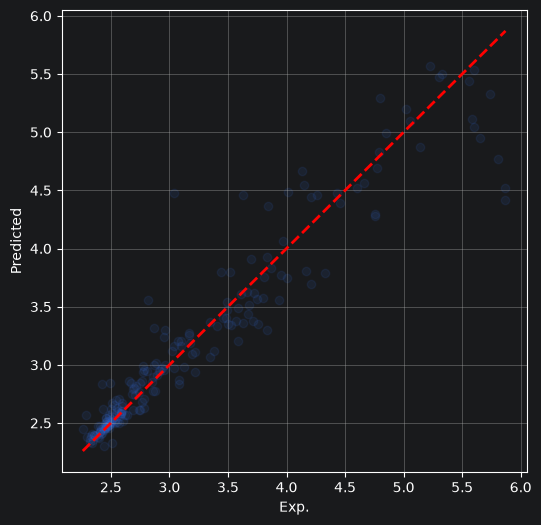

In [16]:
import xgboost as xgb

params = {
        'objective': 'reg:squarederror',
        'max_depth': 9, #6
        'min_child_weight': 0.1, #0-1, 1
        'subsample': 1.0, #0-1, 1
        'colsample_bytree': 0.6, #0-1, 1
        'learning_rate': 0.1,  #0-1, 0.3
        'eta': 0.01,
        'n_estimators': 600
}

# Create a logistic regression model
model = xgb.XGBRegressor(**params, random_state=42, n_jobs=-1)

# Train the model
start_time = time.time()
model.fit(X_train, y_train)
duration = time.time() - start_time

model_plot(model, X_test, y_test, duration)

save_params(model_path, model, 'XGB_Dens_def')

In [17]:
importances = model.feature_importances_

importances_df = pd.DataFrame({'feature': X.columns, 'importance': importances})
importances_df = importances_df.sort_values(by='importance', ascending=False)       

importances_df

,feature,importance
35,MagpieData mean NValence,0.211907
30,MagpieData mean NdValence,0.174350
10,MagpieData mean AtomicWeight,0.135538
34,MagpieData maximum NValence,0.081962
32,MagpieData mean NfValence,0.061971
9,MagpieData maximum AtomicWeight,0.054732
36,MagpieData avg_dev NValence,0.031214
13,MagpieData maximum CovalentRadius,0.028589
17,MagpieData minimum Electronegativity,0.020956
28,MagpieData avg_dev NpValence,0.018345


### Hyperparameters tuning

In [18]:
import xgboost as xgb
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

params = {
    'n_estimators': [100, 200, 500, 1000, 1500],
    'max_depth': [3, 4, 5, 6, 8, 10, 12],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.25, 0.5, 1.0],
    'reg_lambda': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0],
    'reg_alpha': [0, 0.1, 0.5, 1.0, 5.0, 10.0]
}


xgb_regressor = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

# Definicja strategii walidacji krzyżowej (ta sama co poprzednio)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Konfiguracja RandomizedSearchCV dla regresji
random_search_regr = RandomizedSearchCV(
    estimator=xgb_regressor,
    param_distributions=params,
    n_iter=50,
    # KLUCZOWA ZMIANA: Używamy metryki regresyjnej
    # 'neg_root_mean_squared_error' jest dobrą, interpretowalną metryką
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    cv=kfold,
    verbose=1,
    random_state=42
)

# Uruchomienie wyszukiwania
random_search_regr.fit(X_train, y_train)


# Wyświetlenie najlepszych znalezionych hiperparametrów
print("Najlepsze znalezione hiperparametry:")
print(random_search_regr.best_params_)

# Wyświetlenie najlepszego wyniku walidacji krzyżowej
# Wynik będzie ujemny, ponieważ użyliśmy 'neg_root_mean_squared_error'
# Im bliżej zera, tym lepiej.
best_rmse = -random_search_regr.best_score_
print(f"\nNajlepszy wynik RMSE (walidacja krzyżowa): {best_rmse:.4f}")

# Przypisanie najlepszego modelu do zmiennej
best_model = random_search_regr.best_estimator_


# Predykcje na zbiorze testowym
y_pred = best_model.predict(X_test)

# Obliczenie metryk na zbiorze testowym
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nWyniki na zbiorze testowym:")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R^2 Score: {r2:.4f}")

# Interpretacja:
# RMSE/MAE: Średni błąd predykcji w jednostkach zmiennej docelowej. Im niższy, tym lepszy.
# R^2: Procent wariancji w zmiennej docelowej, który jest wyjaśniany przez model. Im bliżej 1, tym lepszy.

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Najlepsze znalezione hiperparametry:
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}

Najlepszy wynik RMSE (walidacja krzyżowa): 0.2644

Wyniki na zbiorze testowym:
Root Mean Squared Error (RMSE): 0.2569
Mean Absolute Error (MAE): 0.1409
R^2 Score: 0.9211


In [19]:
import joblib

# Pobieramy słownik z najlepszymi parametrami z obiektu RandomizedSearchCV
best_params = random_search_regr.best_params_

# Definiujemy nazwę pliku
params_filename = './models/XGB_Dens_best_params.joblib'
model_filename = './models/XGB_Dens_best_model.joblib'

# Zapisujemy słownik do pliku za pomocą joblib.dump()
joblib.dump(best_params, params_filename)
joblib.dump(best_model, model_filename)

print(f"Najlepsze parametry zostały pomyślnie zapisane do pliku: '{params_filename}'")
print("\nZawartość zapisanych parametrów:")
print(best_params)

# --- Jak wczytać te parametry z powrotem? ---
# Wczytujemy obiekt z pliku za pomocą joblib.load()
loaded_params = joblib.load(params_filename)

print(f"\nParametry wczytane z pliku '{params_filename}':")
print(loaded_params)

Najlepsze parametry zostały pomyślnie zapisane do pliku: './models/XGB_Dens_best_params.joblib'

Zawartość zapisanych parametrów:
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}

Parametry wczytane z pliku './models/XGB_Dens_best_params.joblib':
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}


## MLP 

Iteration 1, loss = 3.43970236
Validation score: -6.051685
Iteration 2, loss = 1.12079667
Validation score: -10.763764
Iteration 3, loss = 0.71675728
Validation score: -17.011729
Iteration 4, loss = 0.50942210
Validation score: -12.204587
Iteration 5, loss = 0.26062609
Validation score: -8.712458
Iteration 6, loss = 0.24715735
Validation score: -8.166469
Iteration 7, loss = 0.18016384
Validation score: -8.982534
Iteration 8, loss = 0.14176840
Validation score: -9.242312
Iteration 9, loss = 0.12915647
Validation score: -7.715875
Iteration 10, loss = 0.09851262
Validation score: -6.675940
Iteration 11, loss = 0.09050654
Validation score: -6.391158
Iteration 12, loss = 0.08129459
Validation score: -6.614996
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.
R2: -2.7076
Mean Squared Error: 3.1006
Mean Absolute Error: 1.5944
Fit time: 0.365 s


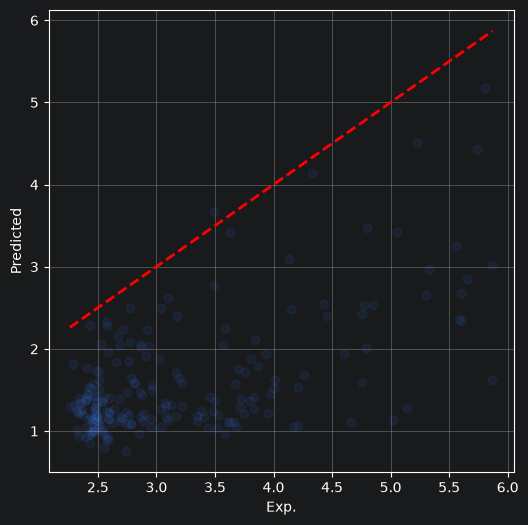

In [20]:
from sklearn.neural_network import MLPRegressor

# Define the parameters for the MLPRegressor
params = {
        'hidden_layer_sizes': (256, 128, 64, 32),  # Tuple representing the number of neurons in each hidden layer
        'max_iter': 500,
        'random_state': 42,
        'verbose': True,
        'activation': 'relu',  # 'identity', 'logistic', 'tanh', 'relu'
        'solver': 'adam',  # 'lbfgs', 'sgd', 'adam'
        'learning_rate': 'adaptive',  # 'constant', 'invscaling', 'adaptive'
        'learning_rate_init': 0.001,  # Initial learning rate used      
        'alpha': 0.0001,  # L2 penalty (regularization term) parameter
        'batch_size': 'auto',  # Size of minibatches for stochastic optimizers
        'early_stopping': True,  # Whether to use early stopping to terminate training when validation score is not improving
        'validation_fraction': 0.1,  # Proportion of training data to set aside as validation set for early stopping
        'n_iter_no_change': 10,  # Number of iterations with no improvement to wait before stopping training
        'max_fun': 15000  # Maximum number of loss function calls                
}

# Create a logistic regression model
model = MLPRegressor(**params)

# Train the model
start_time = time.time()
model.fit(X_train, y_train)
duration = time.time() - start_time

model_plot(model, X_test, y_test, duration)

save_params(model_path, model, 'MLP_Dens_def')

### Hyperparameters tuning


Rozpoczynam przeszukiwanie siatki (Grid Search)... To może chwilę potrwać.
Fitting 3 folds for each of 16 candidates, totalling 48 fits


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END activation=relu, batch_size=auto, hidden_layer_sizes=(256,), learning_rate=adaptive, learning_rate_init=0.0001, solver=adam; total time=   3.2s


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END activation=relu, batch_size=auto, hidden_layer_sizes=(256,), learning_rate=adaptive, learning_rate_init=0.0001, solver=adam; total time=   5.0s


...

[CV] END activation=relu, batch_size=auto, hidden_layer_sizes=(32, 16, 8, 4), learning_rate=adaptive, learning_rate_init=0.0001, solver=adam; total time=   1.2s


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END activation=relu, batch_size=auto, hidden_layer_sizes=(32, 16, 8, 4), learning_rate=adaptive, learning_rate_init=0.0001, solver=adam; total time=   1.1s


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END activation=relu, batch_size=auto, hidden_layer_sizes=(32, 16, 8, 4), learning_rate=adaptive, learning_rate_init=0.0001, solver=adam; total time=   1.2s
Przeszukiwanie siatki zakończone.

--- Wyniki strojenia modelu regresyjnego ---
Najlepsze parametry: {'activation': 'relu', 'batch_size': 'auto', 'hidden_layer_sizes': (128, 64, 32), 'learning_rate': 'adaptive', 'learning_rate_init': 0.0001, 'solver': 'adam'}
Najlepszy wynik (Neg-MSE) z walidacji krzyżowej: -0.22
Odpowiadający mu błąd średniokwadratowy (RMSE): 0.46

--- Ocena najlepszego modelu na zbiorze testowym ---
Ostateczny błąd średniokwadratowy (MSE): 0.11
Ostateczny współczynnik determinacji (R²): 0.8696


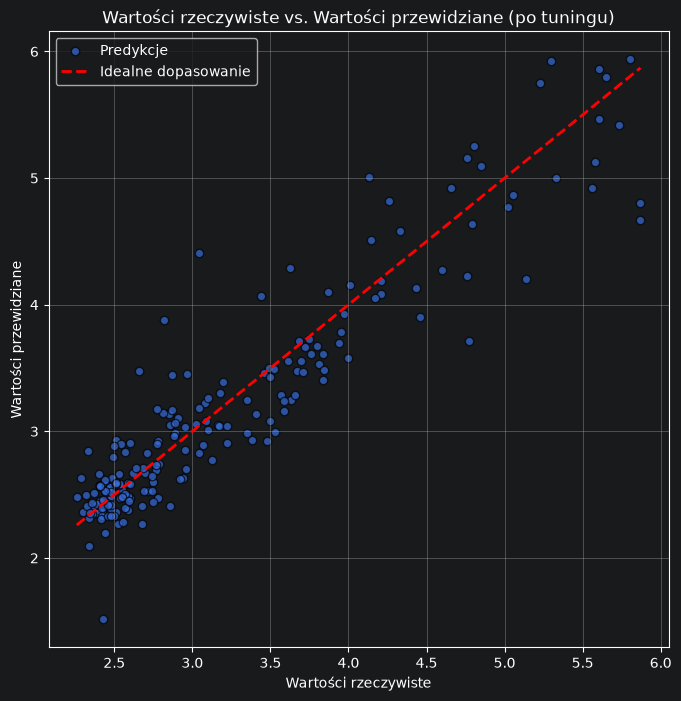

In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor

param_grid = {
    'hidden_layer_sizes': [(256, ), (256, 128), (256, 128, 64), (256, 128, 64, 32), 
                           (128, ), (128, 64), (128, 64, 32), (128, 64, 32, 16), 
                           (64,), (64, 32), (64, 32, 16), (64, 32, 16, 8),
                           (32,), (32, 16), (32, 16, 8), (32, 16, 8, 4)],
    'activation': ['relu'],
    'solver': ['adam'], # Skupiamy się na adam, który jest dobrym domyślnym wyborem
    #'alpha': [0.0001, 0.001, 0.01],  # Regularization term
    'batch_size': ['auto'],  # Możemy zostawić domyśln
    'learning_rate': ['adaptive'],  # 'constant', 'invscaling', 'adaptive'
    'learning_rate_init': [0.0001],  # Initial learning rate used
}


# --- Krok 4: Inicjalizacja i uruchomienie GridSearchCV ---
# Tworzymy bazowy model. Ustawiamy max_iter na wyższą wartość, aby uniknąć
# ostrzeżeń o braku zbieżności podczas przeszukiwania.
base_mlp = MLPRegressor(max_iter=500, random_state=42)

# Tworzymy obiekt GridSearchCV
# estimator: model, który będziemy stroić
# param_grid: nasza siatka parametrów
# cv: liczba podziałów w walidacji krzyżowej (standardowo 3 lub 5)
# scoring: metryka, wg której będziemy oceniać modele (np. 'accuracy', 'f1', 'roc_auc')
# n_jobs=-1: Użyj wszystkich dostępnych rdzeni procesora, aby przyspieszyć obliczenia!
# verbose=2: Wyświetlaj szczegółowe informacje o postępie.

grid_search = GridSearchCV(
    estimator=base_mlp,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    verbose=2
)

print("\nRozpoczynam przeszukiwanie siatki (Grid Search)... To może chwilę potrwać.")
# Uruchamiamy proces strojenia na danych treningowych
grid_search.fit(X_train, y_train)

print("Przeszukiwanie siatki zakończone.")


# --- Krok 5: Analiza wyników strojenia ---
print("\n--- Wyniki strojenia modelu regresyjnego ---")

print(f"Najlepsze parametry: {grid_search.best_params_}")

# best_score_ będzie ujemny. Im bliżej zera, tym lepiej.
best_score_neg_mse = grid_search.best_score_
print(f"Najlepszy wynik (Neg-MSE) z walidacji krzyżowej: {best_score_neg_mse:.2f}")

# Dla lepszej interpretacji możemy obliczyć pierwiastek (RMSE)
best_rmse = np.sqrt(-best_score_neg_mse)
print(f"Odpowiadający mu błąd średniokwadratowy (RMSE): {best_rmse:.2f}")


# --- Krok 6: Ostateczna ocena i wizualizacja najlepszego modelu ---
best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test)

# Oceniamy ostateczny model na zbiorze testowym
final_mse = mean_squared_error(y_test, y_pred_final)
final_r2 = r2_score(y_test, y_pred_final)

print("\n--- Ocena najlepszego modelu na zbiorze testowym ---")
print(f"Ostateczny błąd średniokwadratowy (MSE): {final_mse:.2f}")
print(f"Ostateczny współczynnik determinacji (R²): {final_r2:.4f}")


# Wizualizacja wyników najlepszego modelu
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_final, alpha=0.7, edgecolors='k', label='Predykcje')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Idealne dopasowanie')
plt.title("Wartości rzeczywiste vs. Wartości przewidziane (po tuningu)")
plt.xlabel("Wartości rzeczywiste")
plt.ylabel("Wartości przewidziane")
plt.legend()
plt.grid(True)
plt.show()


In [22]:
import joblib

# Pobieramy słownik z najlepszymi parametrami z obiektu RandomizedSearchCV
best_params = grid_search.best_params_

# Definiujemy nazwę pliku
params_filename = './models/MLP_Dens_best_params.joblib'
model_filename = './models/MLP_Dens_best_model.joblib'

# Zapisujemy słownik do pliku za pomocą joblib.dump()
joblib.dump(best_params, params_filename)
joblib.dump(best_model, model_filename)

print(f"Najlepsze parametry zostały pomyślnie zapisane do pliku: '{params_filename}'")
print("\nZawartość zapisanych parametrów:")
print(best_params)

# --- Jak wczytać te parametry z powrotem? ---
# Wczytujemy obiekt z pliku za pomocą joblib.load()
loaded_params = joblib.load(params_filename)

print(f"\nParametry wczytane z pliku '{params_filename}':")
print(loaded_params)

Najlepsze parametry zostały pomyślnie zapisane do pliku: './models/MLP_Dens_best_params.joblib'

Zawartość zapisanych parametrów:
{'activation': 'relu', 'batch_size': 'auto', 'hidden_layer_sizes': (128, 64, 32), 'learning_rate': 'adaptive', 'learning_rate_init': 0.0001, 'solver': 'adam'}

Parametry wczytane z pliku './models/MLP_Dens_best_params.joblib':
{'activation': 'relu', 'batch_size': 'auto', 'hidden_layer_sizes': (128, 64, 32), 'learning_rate': 'adaptive', 'learning_rate_init': 0.0001, 'solver': 'adam'}
